# Notebook 2 — Credit Risk Exploratory Data Analysis

## Purpose

Explore how borrower, loan, and credit-history characteristics vary with **`target_default_within_12m`** (1 = default within 12 months; 0 = no default within 12 months). This notebook builds on the data-quality checks in Notebook 1 and uses the same synthetic application dataset.

We will compare default rates across important numeric and categorical features, visualize distributions and associations, and inspect unusual observations. All results are descriptive—not evidence of causation or real-world lending behavior. No rows are removed or changed in this EDA.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

# Resolve the same project-relative CSV whether Jupyter starts in the root or notebooks/.
relative_data_path = Path("data/raw/finsight_ai_india_synthetic_5000.csv")
data_path = next(
    (path for path in (relative_data_path, Path("..") / relative_data_path) if path.exists()),
    None,
)
if data_path is None:
    raise FileNotFoundError(
        "Could not find data/raw/finsight_ai_india_synthetic_5000.csv. "
        "Run this notebook from the project root or notebooks/ directory."
    )

df = pd.read_csv(data_path)
target_column = "target_default_within_12m"
if target_column not in df.columns:
    raise ValueError(f"Expected target column {target_column!r} was not found.")
if not df[target_column].dropna().isin([0, 1]).all():
    raise ValueError("The target contains values other than the expected binary labels 0 and 1.")

print(f"Dataset: {data_path.resolve()}")
print(f"Applications: {len(df):,} | Features and target: {df.shape[1]} columns")
print(f"Target missing: {df[target_column].isna().sum():,} | Other fields with missing values: {df.drop(columns=target_column).isna().any().sum()}")
print("\nTarget distribution:")
class_summary = (
    df[target_column]
    .value_counts(dropna=False)
    .sort_index()
    .rename(index={0: "No default (0)", 1: "Default (1)"})
    .rename("applications")
    .to_frame()
)
class_summary["percent"] = (class_summary["applications"] / len(df) * 100).round(2)
display(class_summary)

Dataset: D:\GOURAB DAS\CODE\Git\FinSight AI\data\raw\finsight_ai_india_synthetic_5000.csv
Applications: 5,000 | Features and target: 29 columns
Target missing: 0 | Other fields with missing values: 7

Target distribution:


,applications,percent
target_default_within_12m,,
No default (0),3616,72.32
Default (1),1384,27.68


The analysis uses the same verified 12-month binary target as Notebook 1. In the full dataset, 1,384 applications are labeled default and 3,616 are labeled no default (27.68% vs. 72.32%); the target has no missing labels. The class imbalance makes it more informative to compare group default rates and sample sizes than to rely on counts alone.

## 1. Outcome and borrower-feature distributions

Start with the overall outcome, then compare the ranges and medians of selected continuous features for default and non-default applications. Boxplots omit the individual outlier markers to keep the figure readable; the observations remain in the data, and the next sections quantify unusual values.

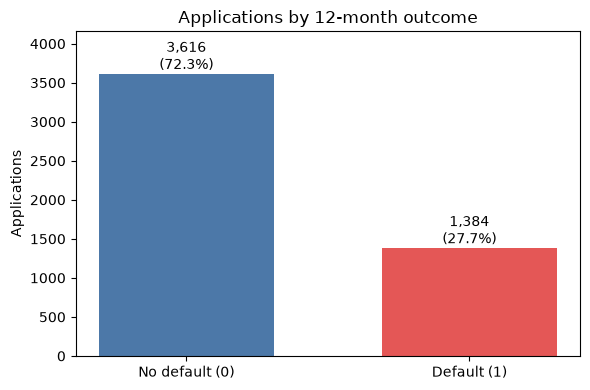

Available observations and medians by outcome; missing values are excluded feature by feature:


No default (0)  Default (1)
age_years                 count         3616.000     1384.000
                          median          43.000       42.000
monthly_net_income_inr    count         3616.000     1384.000
                          median       43123.500    32902.000
debt_to_income_after_loan count         3616.000     1384.000
                          median           0.562        0.883
credit_history_years      count         3467.000     1309.000
                          median           3.400        3.000
credit_inquiries_last_6m  count         3616.000     1384.000
                          median           1.000        1.000
late_payments_last_12m    count         3616.000     1384.000
                          median           0.000        1.000
credit_utilization_ratio  count         3461.000     1328.000
                          median           0.380        0.405

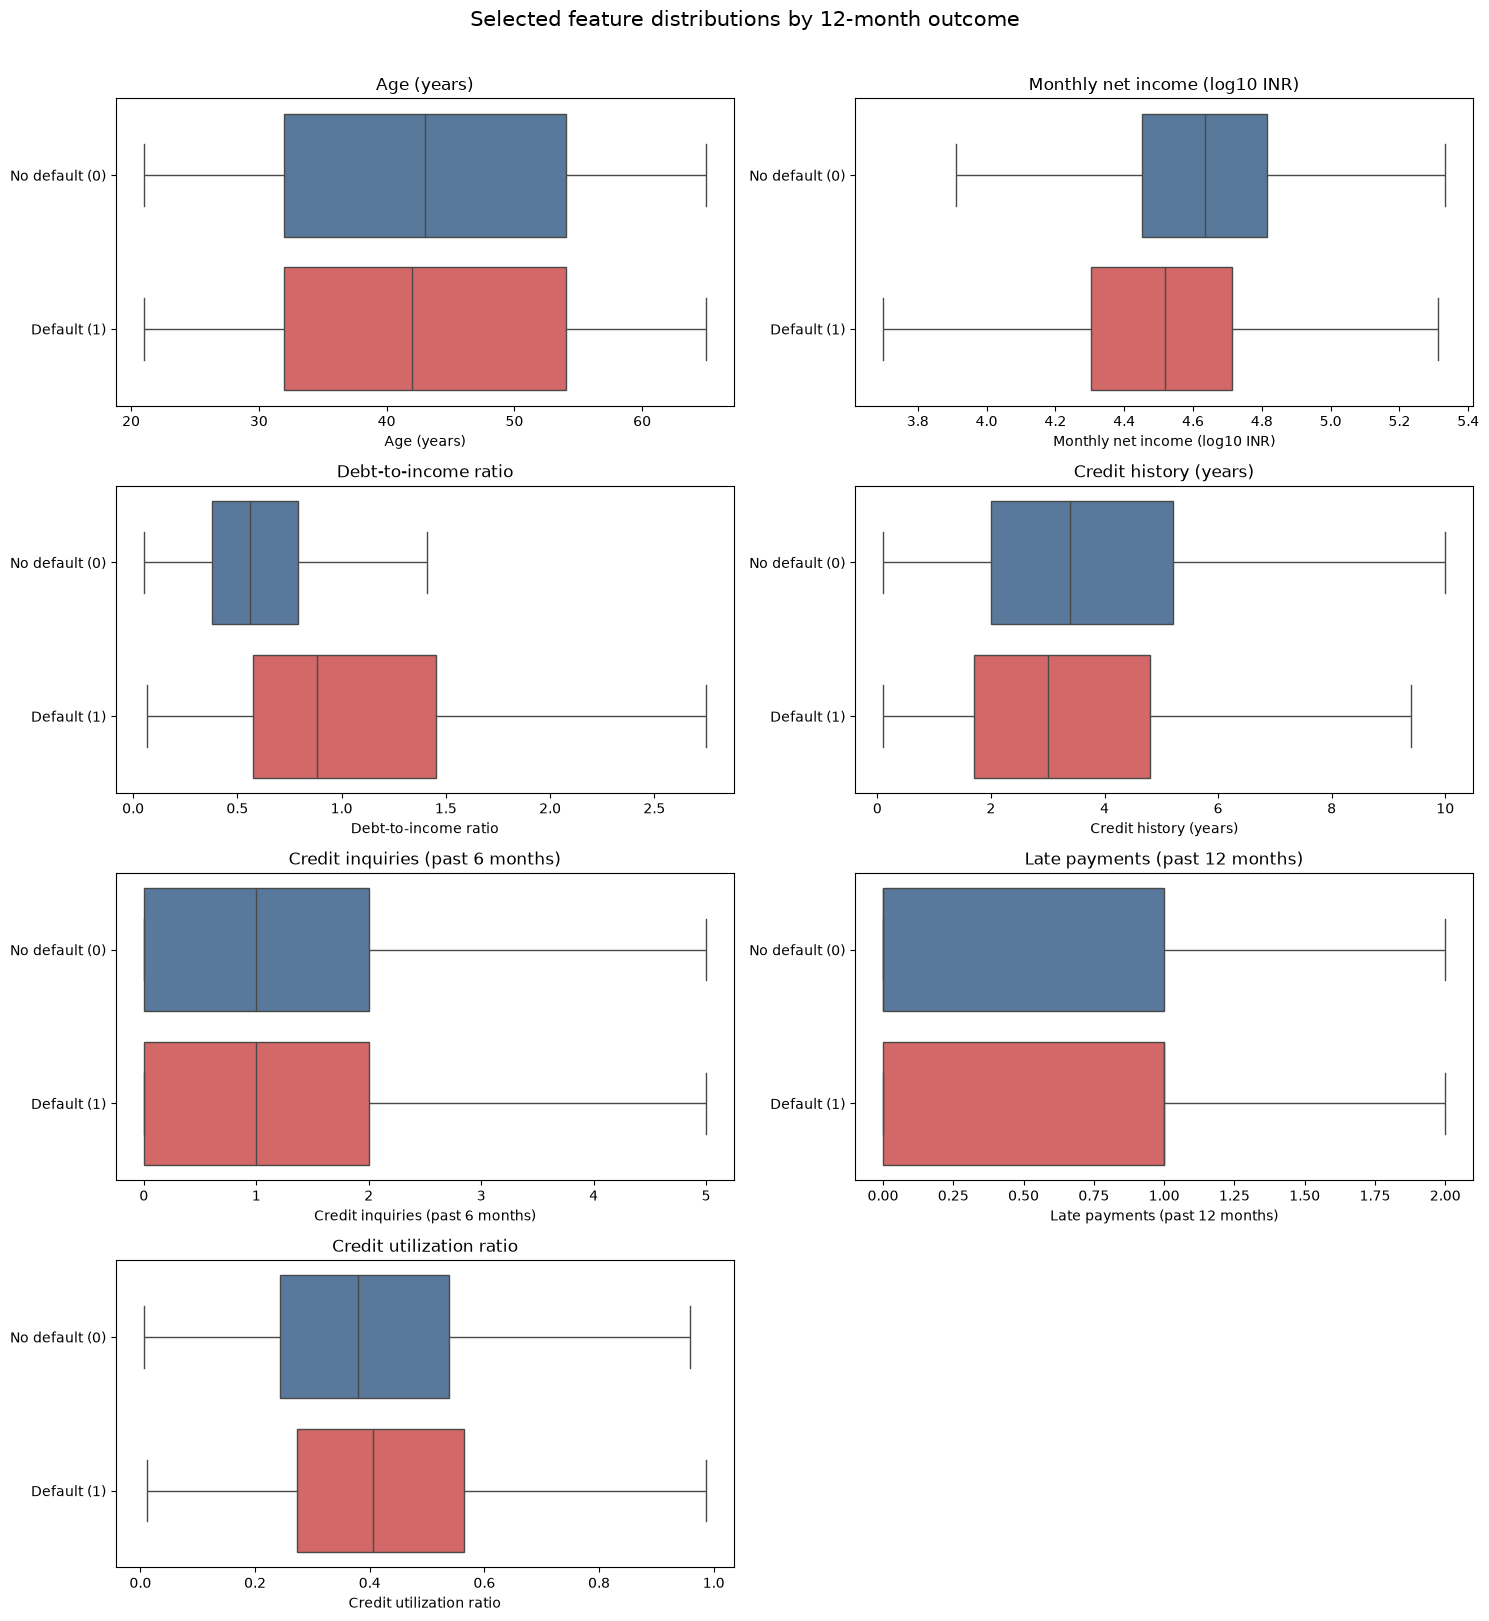

In [2]:
class_counts = df[target_column].value_counts().reindex([0, 1], fill_value=0)
class_labels = ["No default (0)", "Default (1)"]
class_colors = ["#4C78A8", "#E45756"]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(class_labels, class_counts.to_numpy(), color=class_colors, width=0.62)
ax.set_title("Applications by 12-month outcome")
ax.set_ylabel("Applications")
ax.set_ylim(0, class_counts.max() * 1.15)
for bar, count in zip(bars, class_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, count, f"{count:,}\n({count / len(df):.1%})", ha="center", va="bottom")
fig.tight_layout()
plt.show()

comparison_features = [
    "age_years",
    "monthly_net_income_inr",
    "debt_to_income_after_loan",
    "credit_history_years",
    "credit_inquiries_last_6m",
    "late_payments_last_12m",
    "credit_utilization_ratio",
]
outcome_medians = df.groupby(target_column)[comparison_features].agg(["count", "median"]).T
outcome_medians.columns = ["No default (0)", "Default (1)"]
print("Available observations and medians by outcome; missing values are excluded feature by feature:")
display(outcome_medians.round(3))

plot_features = [
    ("age_years", "Age (years)"),
    ("income_log10", "Monthly net income (log10 INR)"),
    ("debt_to_income_after_loan", "Debt-to-income ratio"),
    ("credit_history_years", "Credit history (years)"),
    ("credit_inquiries_last_6m", "Credit inquiries (past 6 months)"),
    ("late_payments_last_12m", "Late payments (past 12 months)"),
    ("credit_utilization_ratio", "Credit utilization ratio"),
    ("loan_log10", "Requested loan amount (log10 INR)"),
]
plot_data = df[[target_column, *comparison_features, "requested_loan_amount_inr"]].copy()
plot_data["income_log10"] = np.log10(plot_data["monthly_net_income_inr"].where(plot_data["monthly_net_income_inr"] > 0))
plot_data["loan_log10"] = np.log10(plot_data["requested_loan_amount_inr"].where(plot_data["requested_loan_amount_inr"] > 0))
plot_data["outcome_label"] = plot_data[target_column].map({0: "No default (0)", 1: "Default (1)"})

fig, axes = plt.subplots(4, 2, figsize=(15, 16))
for ax, (feature, label) in zip(axes.flat, plot_features):
    sns.boxplot(
        data=plot_data,
        x=feature,
        y="outcome_label",
        hue="outcome_label",
        order=class_labels,
        hue_order=class_labels,
        palette=dict(zip(class_labels, class_colors)),
        showfliers=False,
        legend=False,
        ax=ax,
    )
    ax.set_title(label)
    ax.set_xlabel(label)
    ax.set_ylabel("")
axes.flat[-1].set_visible(False)
fig.suptitle("Selected feature distributions by 12-month outcome", fontsize=15, y=1.01)
fig.tight_layout()
plt.show()

The class chart shows the baseline outcome mix; the boxplots and median table help compare typical applicants without hiding feature-specific missingness. Log-scaled income and loan amount are plotted to make their central ranges visible alongside long upper tails. Differences between classes are descriptive only: overlapping distributions are expected, medians do not establish an individual applicant's risk, and these fields' measurement timing still needs confirmation before they can be used in a model.

## 2. Default rates across numeric-feature bands

Compare the observed default rate across quartiles of income, post-loan debt-to-income ratio, prior late payments, credit-history length, and utilization. Quartiles are calculated separately for each feature. Missing feature values are excluded from that feature's bands, not from the source dataset.

Observed 12-month default rates by feature quartile:


,feature,band,applications,default_rate_percent
0,Monthly net income (INR),"(4999.999, 25912.5]",1250,39.0
1,Monthly net income (INR),"(25912.5, 40177.5]",1250,29.5
2,Monthly net income (INR),"(40177.5, 61397.0]",1250,23.0
3,Monthly net income (INR),"(61397.0, 398564.0]",1250,19.2
4,Debt-to-income ratio,"(0.0503, 0.417]",1250,13.0
5,Debt-to-income ratio,"(0.417, 0.627]",1250,18.7
6,Debt-to-income ratio,"(0.627, 0.926]",1250,26.4
7,Debt-to-income ratio,"(0.926, 27.73]",1250,52.6
8,Late payments in the past 12 months,"(-0.001, 1.0]",4320,25.9
9,Late payments in the past 12 months,"(1.0, 5.0]",680,38.7


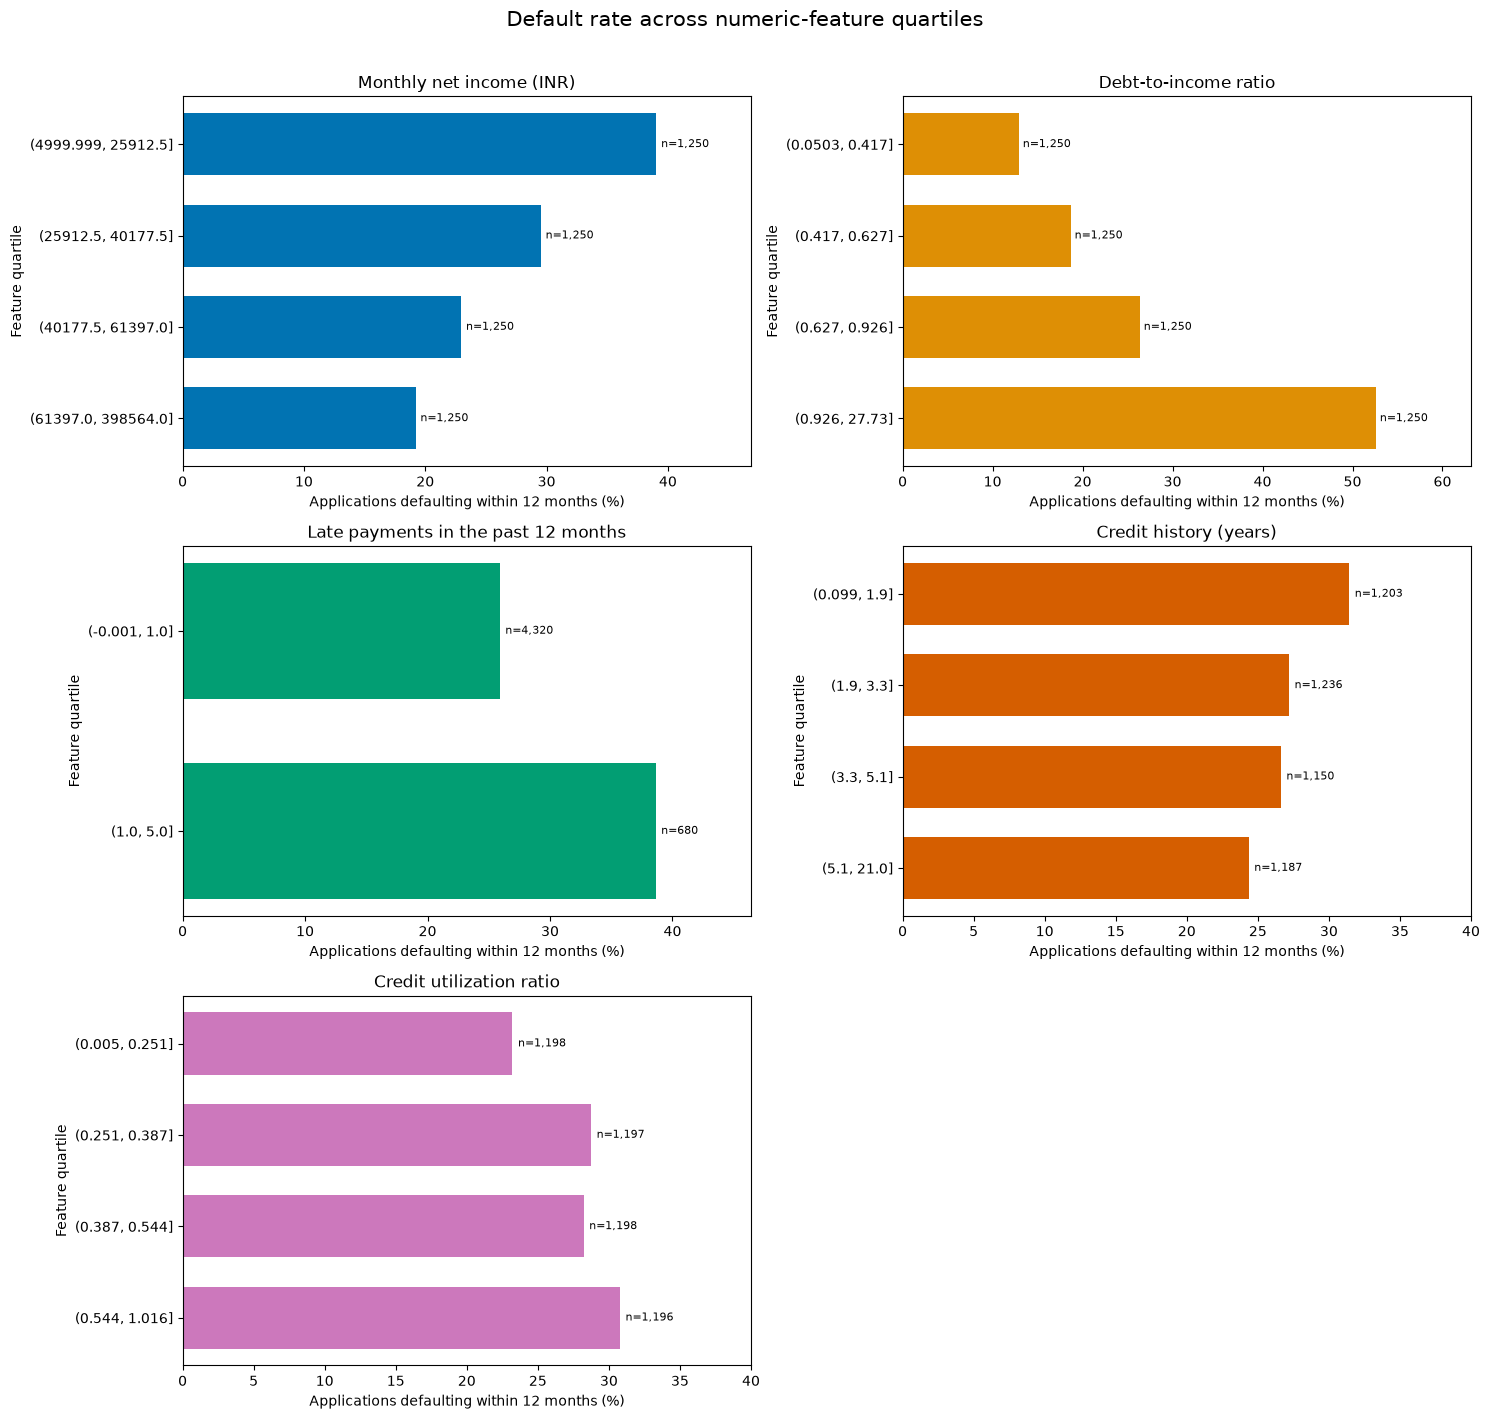

Monthly net income (INR): 0 missing values excluded from its quartile comparison.
Debt-to-income ratio: 0 missing values excluded from its quartile comparison.
Late payments in the past 12 months: 0 missing values excluded from its quartile comparison.
Credit history (years): 224 missing values excluded from its quartile comparison.
Credit utilization ratio: 211 missing values excluded from its quartile comparison.


In [3]:
numeric_segment_features = [
    "monthly_net_income_inr",
    "debt_to_income_after_loan",
    "late_payments_last_12m",
    "credit_history_years",
    "credit_utilization_ratio",
]
segment_labels = {
    "monthly_net_income_inr": "Monthly net income (INR)",
    "debt_to_income_after_loan": "Debt-to-income ratio",
    "late_payments_last_12m": "Late payments in the past 12 months",
    "credit_history_years": "Credit history (years)",
    "credit_utilization_ratio": "Credit utilization ratio",
}
numeric_segment_tables = {}

for feature in numeric_segment_features:
    bands = pd.qcut(df[feature], q=4, duplicates="drop")
    grouped = df.groupby(bands, observed=True)[target_column].agg(
        applications="size", default_rate="mean"
    )
    grouped["default_percent"] = grouped["default_rate"] * 100
    grouped["feature"] = segment_labels[feature]
    grouped["band"] = grouped.index.astype(str)
    numeric_segment_tables[feature] = grouped.reset_index(drop=True)

numeric_segments = pd.concat(numeric_segment_tables.values(), ignore_index=True)
print("Observed 12-month default rates by feature quartile:")
display(
    numeric_segments[["feature", "band", "applications", "default_percent"]]
    .rename(columns={"default_percent": "default_rate_percent"})
    .round({"default_rate_percent": 1})
)

fig, axes = plt.subplots(3, 2, figsize=(15, 14))
feature_colors = sns.color_palette("colorblind", n_colors=len(numeric_segment_features))
for ax, feature, color in zip(axes.flat, numeric_segment_features, feature_colors):
    table = numeric_segment_tables[feature]
    ax.barh(table["band"], table["default_percent"], color=color, height=0.68)
    ax.invert_yaxis()
    ax.set_title(segment_labels[feature])
    ax.set_xlabel("Applications defaulting within 12 months (%)")
    ax.set_ylabel("Feature quartile")
    ax.set_xlim(0, max(40, table["default_percent"].max() * 1.2))
    for y_position, (_, row) in enumerate(table.iterrows()):
        ax.text(row["default_percent"] + 0.4, y_position, f"n={row['applications']:,}", va="center", fontsize=8)
axes.flat[-1].set_visible(False)
fig.suptitle("Default rate across numeric-feature quartiles", fontsize=15, y=1.01)
fig.tight_layout()
plt.show()

for feature in numeric_segment_features:
    missing_count = int(df[feature].isna().sum())
    print(f"{segment_labels[feature]}: {missing_count:,} missing values excluded from its quartile comparison.")

Quartile comparisons reveal whether observed default frequency varies across the range of each characteristic; the counts beside each bar put those percentages in context. Ties can produce fewer than four distinct quartiles, particularly for count variables. These bands are descriptive summaries, not causal effects, calibrated individual probabilities, or evidence that a feature was known at application time.

## 3. Default rates across applicant and loan categories

Compare target prevalence across employment type, city tier, education, loan purpose, repayment method, and state. Show the application count as well as a 95% Wilson interval for each observed group rate. For readability, plots omit groups with fewer than 30 applications; the accompanying table still reports every group.

Application counts, observed default rates, and Wilson intervals by category:


,feature,category,applications,defaults,default_rate_percent,95%_ci_lower_percent,95%_ci_upper_percent
0,employment_type,Unemployed,260,140,53.8,47.8,59.8
1,employment_type,Agriculture,307,108,35.2,30.1,40.7
2,employment_type,Gig/Contract,484,156,32.2,28.2,36.5
3,employment_type,Self-employed,1042,272,26.1,23.5,28.9
4,employment_type,Salaried,2339,586,25.1,23.3,26.8
5,employment_type,Business owner,568,122,21.5,18.3,25.0
6,city_tier,Tier 3/Rural,1314,426,32.4,29.9,35.0
7,city_tier,Tier 2,1893,510,26.9,25.0,29.0
8,city_tier,Tier 1,1793,448,25.0,23.0,27.0
9,education_level,Diploma,522,170,32.6,28.7,36.7


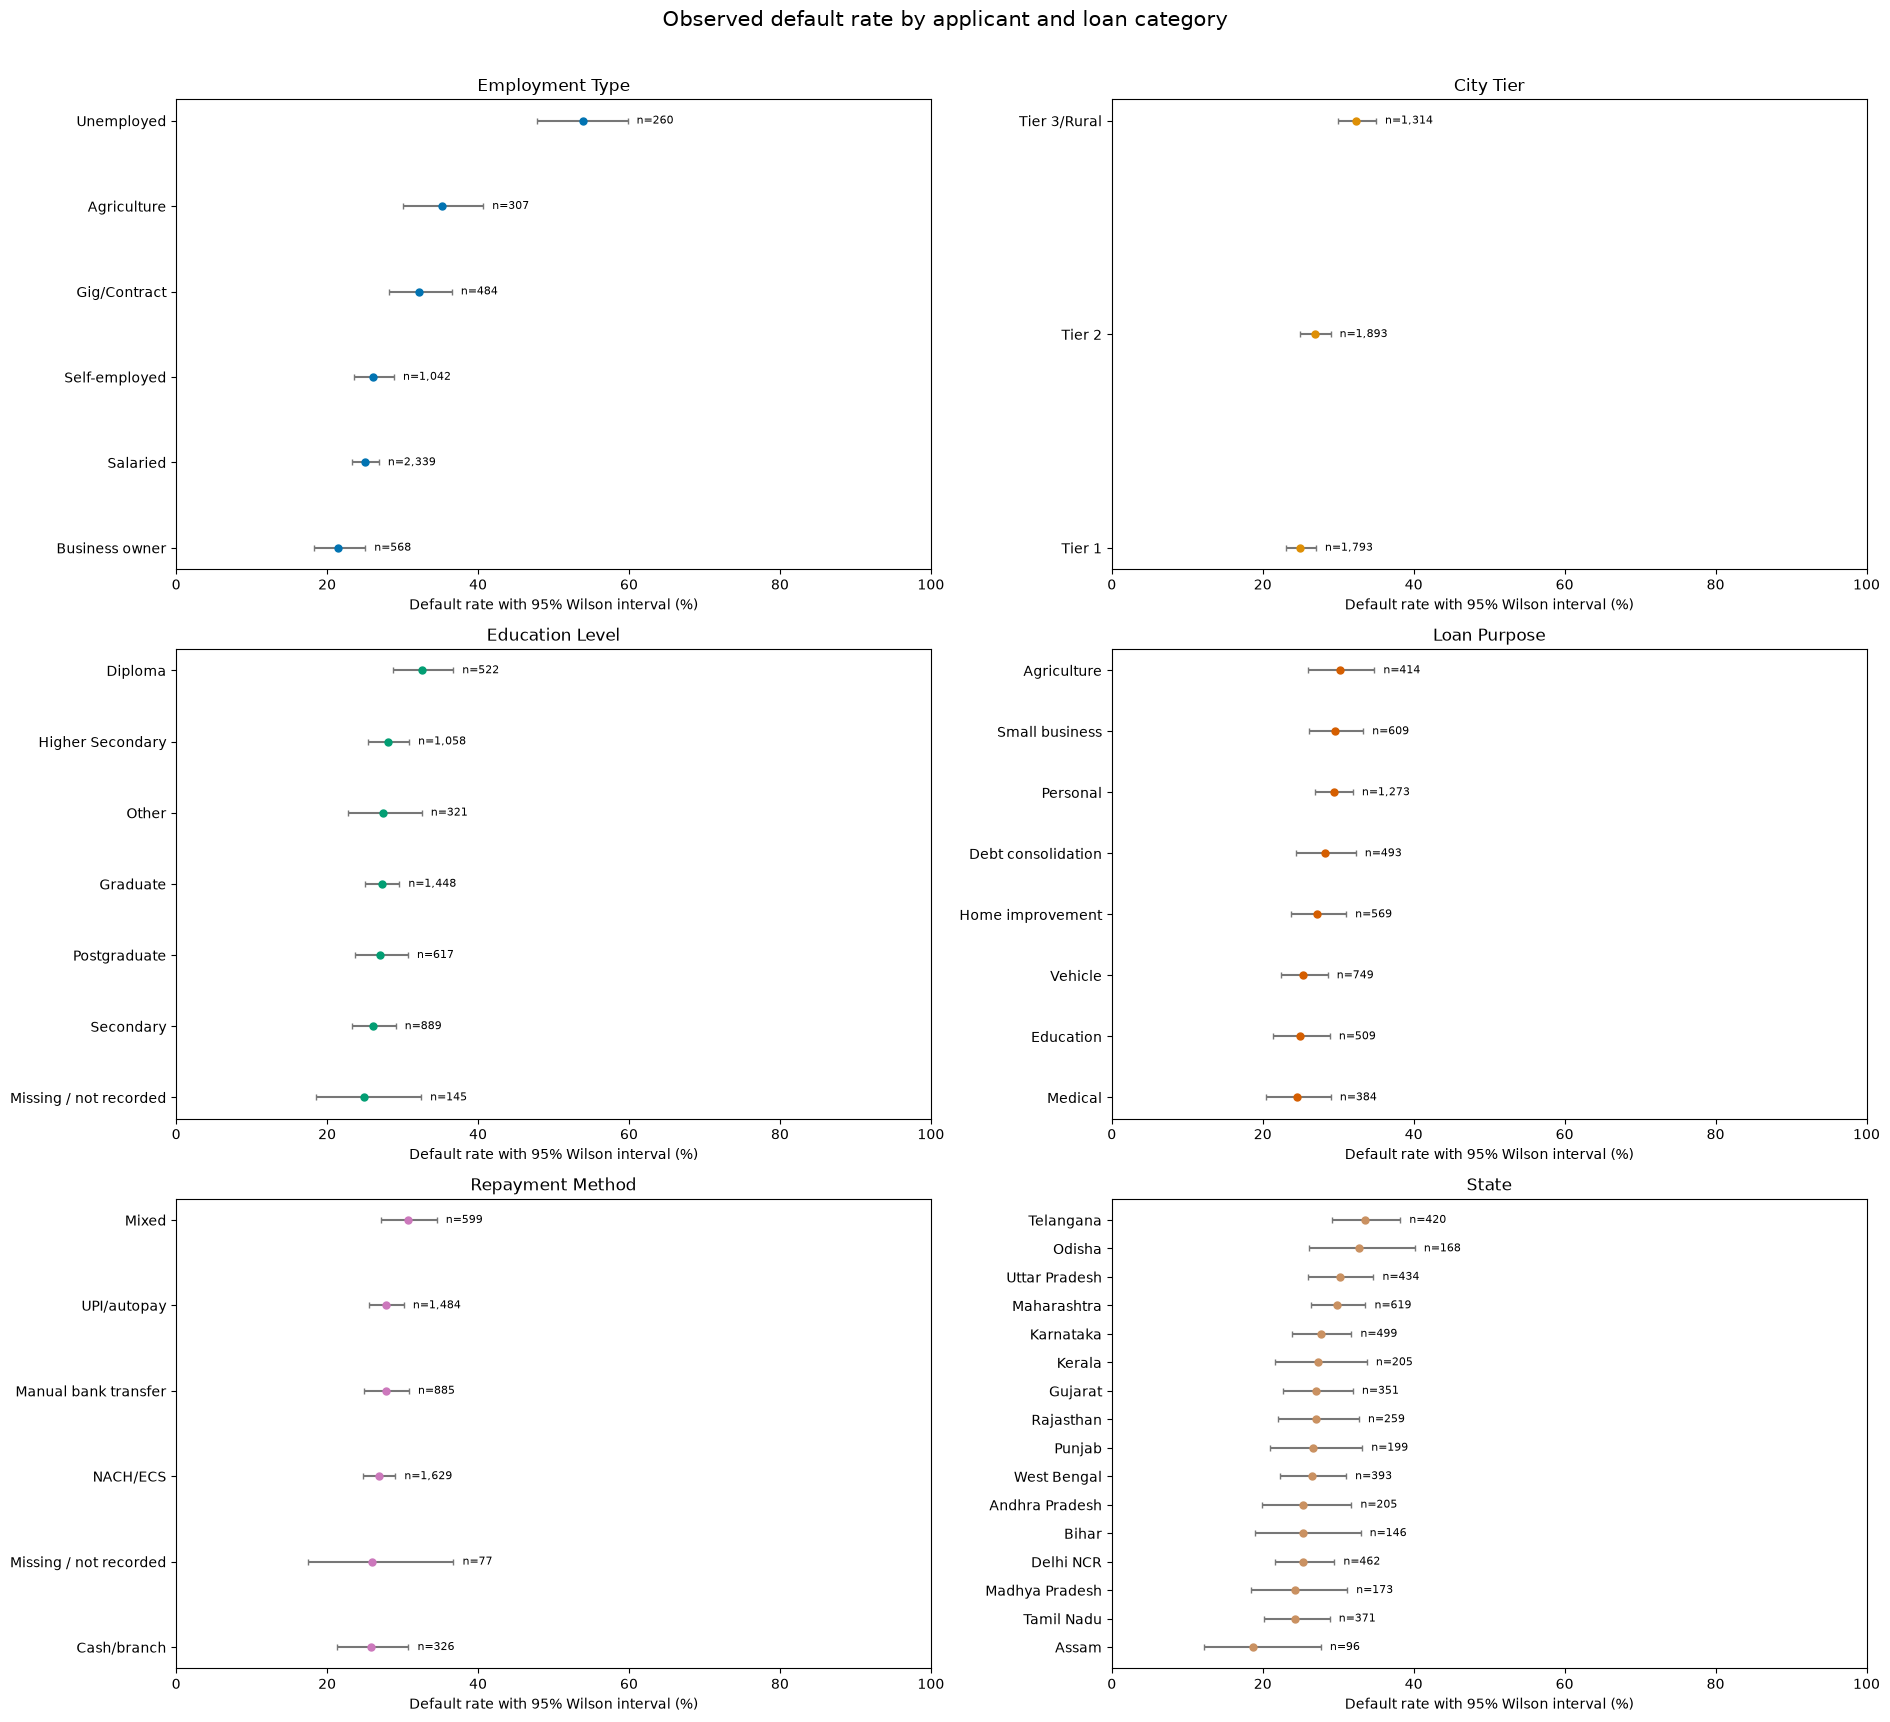

In [4]:
categorical_segment_features = [
    "employment_type",
    "city_tier",
    "education_level",
    "loan_purpose",
    "repayment_method",
    "state",
]

def wilson_interval(successes, total, z_score=1.96):
    """Return the 95% Wilson interval for a binomial proportion."""
    if total == 0:
        return np.nan, np.nan
    rate = successes / total
    denominator = 1 + z_score**2 / total
    midpoint = (rate + z_score**2 / (2 * total)) / denominator
    margin = z_score * np.sqrt(
        rate * (1 - rate) / total + z_score**2 / (4 * total**2)
    ) / denominator
    return max(0, midpoint - margin), min(1, midpoint + margin)

categorical_segment_tables = {}
for feature in categorical_segment_features:
    table = (
        df.groupby(feature, dropna=False, observed=True)[target_column]
        .agg(applications="size", defaults="sum", default_rate="mean")
        .reset_index()
        .rename(columns={feature: "category"})
    )
    table["category"] = table["category"].astype("string").fillna("Missing / not recorded")
    intervals = [
        wilson_interval(int(row.defaults), int(row.applications))
        for row in table.itertuples(index=False)
    ]
    table["ci_lower"] = [interval[0] for interval in intervals]
    table["ci_upper"] = [interval[1] for interval in intervals]
    table["default_percent"] = table["default_rate"] * 100
    table["ci_lower_percent"] = table["ci_lower"] * 100
    table["ci_upper_percent"] = table["ci_upper"] * 100
    categorical_segment_tables[feature] = table.sort_values("default_rate", ascending=False)

categorical_segments = pd.concat(
    [table.assign(feature=feature) for feature, table in categorical_segment_tables.items()],
    ignore_index=True,
)
print("Application counts, observed default rates, and Wilson intervals by category:")
display(
    categorical_segments[
        ["feature", "category", "applications", "defaults", "default_percent", "ci_lower_percent", "ci_upper_percent"]
    ]
    .rename(
        columns={
            "default_percent": "default_rate_percent",
            "ci_lower_percent": "95%_ci_lower_percent",
            "ci_upper_percent": "95%_ci_upper_percent",
        }
    )
    .round(1)
)

fig, axes = plt.subplots(3, 2, figsize=(19, 17))
feature_colors = sns.color_palette("colorblind", n_colors=len(categorical_segment_features))
minimum_group_size = 30
for ax, feature, color in zip(axes.flat, categorical_segment_features, feature_colors):
    plot_table = categorical_segment_tables[feature].query("applications >= @minimum_group_size").copy()
    plot_table = plot_table.sort_values("default_rate", ascending=True)
    y_positions = np.arange(len(plot_table))
    ax.errorbar(
        plot_table["default_percent"],
        y_positions,
        xerr=np.vstack(
            [
                plot_table["default_percent"] - plot_table["ci_lower_percent"],
                plot_table["ci_upper_percent"] - plot_table["default_percent"],
            ]
        ),
        fmt="o",
        color=color,
        ecolor="#777777",
        capsize=2,
        markersize=5,
    )
    ax.set_yticks(y_positions, labels=plot_table["category"].astype(str))
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("Default rate with 95% Wilson interval (%)")
    ax.set_ylabel("")
    ax.set_xlim(0, 100)
    for y_position, (_, row) in enumerate(plot_table.iterrows()):
        ax.text(min(row["ci_upper_percent"] + 1.2, 94), y_position, f"n={int(row['applications']):,}", va="center", fontsize=8)
    omitted_groups = int((categorical_segment_tables[feature]["applications"] < minimum_group_size).sum())
    if omitted_groups:
        ax.text(0.99, 0.02, f"{omitted_groups} group(s) under n={minimum_group_size} not plotted", transform=ax.transAxes, ha="right", va="bottom", fontsize=8)
fig.suptitle("Observed default rate by applicant and loan category", fontsize=15, y=1.01)
fig.tight_layout()
plt.show()

The intervals communicate sampling uncertainty around each observed subgroup rate, while the adjacent counts show where a comparison is based on fewer cases. Overlapping intervals are a reason to be cautious about ranking categories—not a formal test of equivalence or difference. State-level patterns are exploratory and synthetic; they do not justify geographic, employment, education, or other real-world lending decisions. The observation date of `repayment_method` is not documented, so this field may be post-application and should not be assumed to be a permissible predictor.

## 4. Numeric feature associations

Use pairwise Spearman correlations to screen for monotonic associations with the binary outcome and for redundant numeric predictors. Exclude the target from predictors, as well as `application_id`, the exact duplicate `ead_assumption_inr`, and `lgd_assumption`, which Notebook 1 identified as an unverified loss-scenario assumption. Pairwise correlations use available observations and are not causal estimates.

Numeric predictors most strongly associated with the target by absolute Spearman correlation:


,spearman_correlation_with_target
debt_to_income_after_loan,0.329
estimated_emi_inr,0.212
monthly_net_income_inr,-0.186
requested_loan_amount_inr,0.165
late_payments_last_12m,0.149
loan_tenure_months,-0.134
prior_default_flag,0.089
employment_years,-0.086
existing_monthly_debt_inr,-0.061
credit_utilization_ratio,0.061


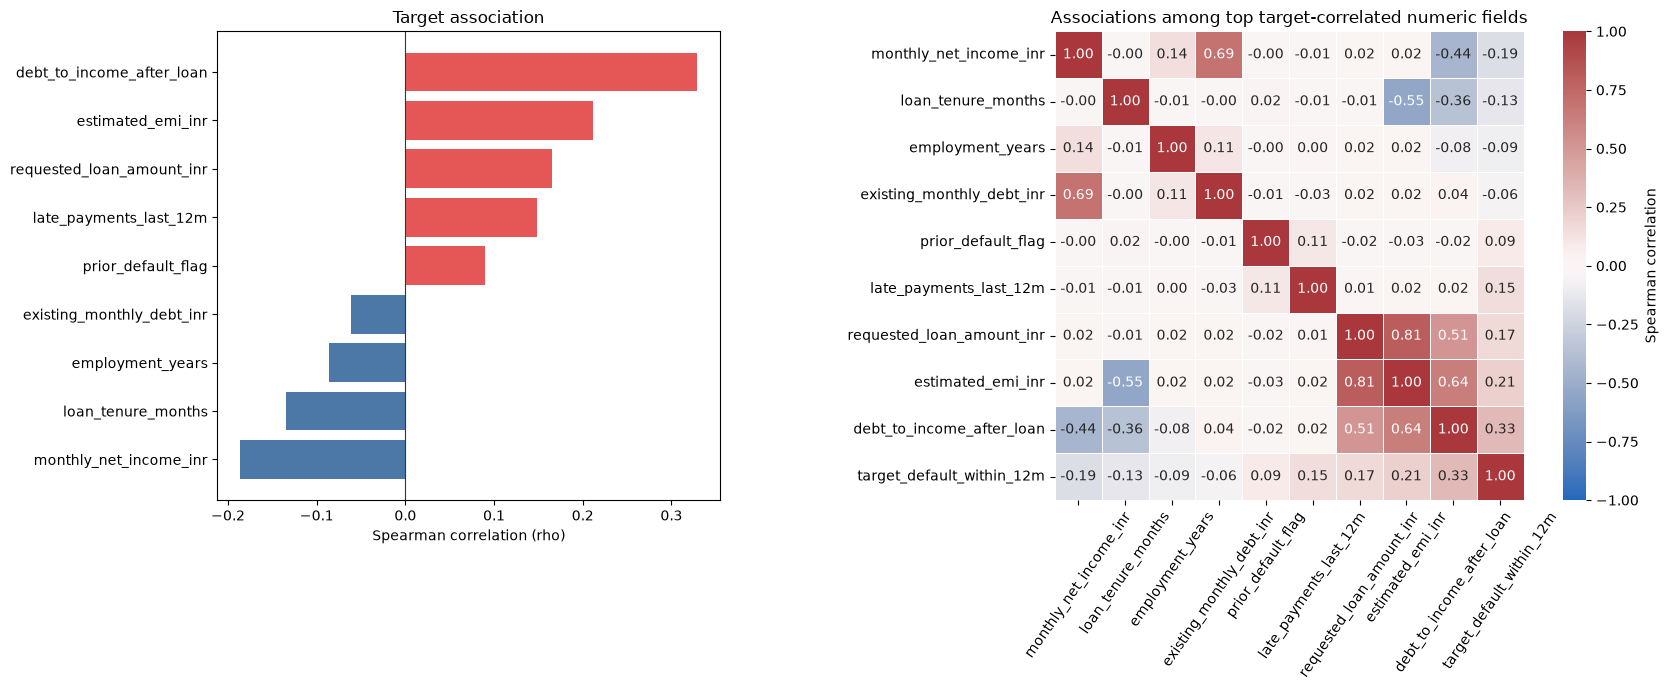

In [5]:
excluded_numeric_columns = {
    target_column,
    "application_id",
    "ead_assumption_inr",
    "lgd_assumption",
}
numeric_predictors = [
    column
    for column in df.select_dtypes(include="number").columns
    if column not in excluded_numeric_columns
]
correlation_data = df[numeric_predictors + [target_column]]
correlation_matrix = correlation_data.corr(method="spearman", min_periods=30)
target_correlations = (
    correlation_matrix[target_column]
    .drop(labels=target_column)
    .dropna()
    .sort_values(key=lambda values: values.abs(), ascending=False)
)

print("Numeric predictors most strongly associated with the target by absolute Spearman correlation:")
display(
    target_correlations.head(10)
    .rename("spearman_correlation_with_target")
    .to_frame()
    .round(3)
)

top_features = target_correlations.head(9).index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={"width_ratios": [0.9, 1.4]})
top_correlations = target_correlations.reindex(top_features).sort_values()
axes[0].barh(top_correlations.index, top_correlations.values, color=["#E45756" if value > 0 else "#4C78A8" for value in top_correlations.values])
axes[0].axvline(0, color="#333333", linewidth=0.8)
axes[0].set_title("Target association")
axes[0].set_xlabel("Spearman correlation (rho)")
axes[0].set_ylabel("")

heatmap_features = top_correlations.index.tolist() + [target_column]
sns.heatmap(
    correlation_matrix.loc[heatmap_features, heatmap_features],
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.4,
    cbar_kws={"label": "Spearman correlation"},
    ax=axes[1],
)
axes[1].set_title("Associations among top target-correlated numeric fields")
axes[1].tick_params(axis="x", labelrotation=55)
axes[1].tick_params(axis="y", labelrotation=0)
fig.tight_layout()
plt.show()

The ranked table and heatmap help identify candidate risk signals and pairs of features that may carry overlapping information. Correlation is a univariate, pairwise screen: it cannot establish causation, detect all nonlinear relationships, or determine predictive value after adjustment for other fields. Features computed after a lending decision or observed during the target window may still leak outcome information even when their correlation appears plausible.

## 5. Unusual observations and interpretation limits

Use the interquartile-range rule to flag unusually low or high values in selected numeric features. IQR flags describe the tails of these particular distributions; they are not a standard of truth, and a valid applicant can be an outlier. Review the counts and example records before making cleaning decisions.

In [6]:
outlier_features = [
    "age_years",
    "monthly_net_income_inr",
    "existing_monthly_debt_inr",
    "requested_loan_amount_inr",
    "estimated_emi_inr",
    "debt_to_income_after_loan",
    "credit_utilization_ratio",
    "savings_balance_inr",
]
outlier_rows = []
for feature in outlier_features:
    values = df[feature].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    spread = q3 - q1
    lower_fence = q1 - 1.5 * spread
    upper_fence = q3 + 1.5 * spread
    flagged = df[feature].lt(lower_fence) | df[feature].gt(upper_fence)
    outlier_rows.append(
        {
            "feature": feature,
            "observed_count": int(values.size),
            "lower_fence": lower_fence,
            "upper_fence": upper_fence,
            "flagged_applications": int(flagged.sum()),
            "percent_of_all_applications": 100 * flagged.mean(),
            "observed_minimum": values.min(),
            "observed_maximum": values.max(),
        }
    )

iqr_review = pd.DataFrame(outlier_rows).set_index("feature")
print("IQR-fence review (flag counts use all applications as the percentage denominator):")
display(iqr_review.round(2))

examples = df.nlargest(5, "debt_to_income_after_loan")[
    [
        "application_id",
        "age_years",
        "monthly_net_income_inr",
        "existing_monthly_debt_inr",
        "estimated_emi_inr",
        "debt_to_income_after_loan",
        target_column,
    ]
].copy()
print("Five applications with the highest post-loan debt-to-income ratio (examples for validation, not automatic exclusions):")
display(examples)

target_values = sorted(df[target_column].dropna().unique().tolist())
print(f"The target itself is binary ({target_values}); it has no continuous-value outliers.")
print("Rows flagged by the IQR rule are retained; investigate source definitions and verify each record before proposing corrections.")

IQR-fence review (flag counts use all applications as the percentage denominator):


,observed_count,lower_fence,upper_fence,flagged_applications,percent_of_all_applications,observed_minimum,observed_maximum
feature,,,,,,,
age_years,5000,-1.00,87.00,0,0.00,21.00,65.00
monthly_net_income_inr,5000,-27314.25,114623.75,244,4.88,5000.00,398564.00
existing_monthly_debt_inr,5000,-16466.50,43305.50,280,5.60,70.00,192706.00
requested_loan_amount_inr,5000,-218069.62,717739.38,283,5.66,17775.00,2500000.00
estimated_emi_inr,5000,-14586.75,38265.25,396,7.92,372.00,300394.00
debt_to_income_after_loan,5000,-0.35,1.69,382,7.64,0.05,27.73
credit_utilization_ratio,4789,-0.19,0.98,2,0.04,0.01,1.02
savings_balance_inr,4848,-91239.12,246493.88,371,7.42,1733.00,1617802.00


Five applications with the highest post-loan debt-to-income ratio (examples for validation, not automatic exclusions):


,application_id,age_years,monthly_net_income_inr,existing_monthly_debt_inr,estimated_emi_inr,debt_to_income_after_loan,target_default_within_12m
587,FIN000588,25,6818,1517,187545,27.7298,1
421,FIN000422,56,7408,1863,194666,26.5293,1
2731,FIN002732,33,26464,8005,300394,11.6535,1
2912,FIN002913,59,5000,1074,47203,9.6554,1
3671,FIN003672,53,7988,5674,70794,9.5729,0


The target itself is binary ([0, 1]); it has no continuous-value outliers.
Rows flagged by the IQR rule are retained; investigate source definitions and verify each record before proposing corrections.


A boxplot or IQR flag identifies statistical extremeness, not data corruption. In particular, income, savings, requested exposure, EMI, and debt ratios can have legitimate long-tailed distributions. The binary target has no meaningful continuous outliers. Cross-check extreme or contradictory values with data definitions and source records; do not winsorize or drop them solely to make plots or future model metrics look cleaner.

## EDA Summary

### Q&A

- **Which borrower and loan characteristics vary with the observed default outcome?** Compare the outcome medians, numeric quartile default rates, category-level rates with Wilson intervals, and pairwise Spearman associations above. These describe associations in this synthetic sample; they do not identify causal drivers or predict an individual application.
- **Are there unusual patterns or outliers?** The numeric IQR table and highest debt-to-income examples show how often the selected features exceed conventional distribution-based fences. Such records remain valid unless independently checked against business rules and source data; the binary target itself has no continuous outliers.

### Data Analysis Key Findings

- The dataset contains 5,000 synthetic applications; 1,384 (27.68%) are labeled as default within 12 months and 3,616 (72.32%) as no default. No target labels are missing.
- The default group's median post-loan debt-to-income ratio is 0.883 versus 0.562 for non-defaults; median monthly income is INR 32,902 versus INR 43,123.50. These are sample-level associations, not causal effects.
- Default prevalence increases across debt-to-income quartiles in this sample: 13.0% in the lowest band (up to 0.417) versus 52.6% in the highest band (above 0.926). The highest-income quartile has a 19.2% default rate versus 39.0% in the lowest-income quartile. These groups are unadjusted descriptive comparisons.
- Debt-to-income has the strongest numeric Spearman association with the target (rho = 0.329), followed by estimated EMI (0.212) and monthly income (-0.186). No correlation establishes causation or excludes leakage.
- An IQR review flags 382 debt-to-income observations (7.64%) above the upper fence of 1.69; the maximum is 27.73. IQR flags describe distribution tails, not necessarily invalid records. No rows were removed and no missing values were imputed.

### Insights or Next Steps

- Before modeling, confirm that each candidate predictor was available at prediction time, particularly loan terms, repayment method, and prior-default history; exclude the application ID, duplicate EAD field, and unverified LGD assumption.
- In the supervised-modeling notebook, use leakage-aware preprocessing and validation, preserve the unmodified records, and evaluate class-sensitive metrics. These synthetic associations should not be generalized to real borrowers or used for real lending decisions.